<a href="https://colab.research.google.com/github/mariajosseu/DL-PINNS-project/blob/main/Task2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2


In [ ]:
 # imports
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import math

In [ ]:
#constants
m = 1.0 # mass
mu = 5 # friction constant
k = 500 # spring constant

omega_intial = np.sqrt(k)
delta = mu/(2*m)
omega = np.sqrt(omega_intial**2 - delta**2)

def A(phi):
    return 1 / (2*math.cos(phi))

phi = np.arctan(-1*delta/omega)

print(np.exp(-1*delta*1))
print("delta =, ", delta)
print("A(phi) = ", A(phi))
print("phi = ", phi)
print("omega = ", omega)

def x(t):
    return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


0.0820849986238988
delta =,  2.5
A(phi) =  0.5031546054266276
phi =  -0.11203764265090964
omega =  22.22048604328897


## Task 2.1

In [ ]:
t_train = torch.linspace(start = 0, end = 0.5, steps = 10)
t_train = t_train.view(-1,1) # We transform it into shape (samples, features), instead of (samples). In our case that is (10,1)

y_train = x(t_train)


/tmp/ipykernel_1143/2512189505.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


In [ ]:
t_train, y_train

(tensor([[0.0000],
         [0.0556],
         [0.1111],
         [0.1667],
         [0.2222],
         [0.2778],
         [0.3333],
         [0.3889],
         [0.4444],
         [0.5000]]),
 tensor([[ 1.0000e+00],
         [ 3.7966e-01],
         [-5.3937e-01],
         [-5.9742e-01],
         [ 6.5368e-02],
         [ 4.9007e-01],
         [ 2.3201e-01],
         [-2.3794e-01],
         [-3.1242e-01],
         [ 7.5852e-04]]))

## Task 2.2

In [ ]:
class Net(nn.Module):
    def __init__(self):
        super(Net,self).__init__()
        activation = nn.Tanh()
        self.net = nn.Sequential(
            nn.Linear(1, 10),
            activation,
            nn.Linear(10, 1),
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
model = Net()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

num_epoch = 10000
model.train()
for epoch in range(num_epoch):
    optimizer.zero_grad()
    outputs = model(t_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    if (epoch+1) % 1 == 0:
        print(f'Epoch [{epoch+1}/{num_epoch}], Loss: {loss.item():.4f}')

Streaming output truncated to the last 5000 lines.
Epoch [5001/10000], Loss: 0.0002
Epoch [5002/10000], Loss: 0.0002
Epoch [5003/10000], Loss: 0.0002
Epoch [5004/10000], Loss: 0.0002
Epoch [5005/10000], Loss: 0.0002
Epoch [5006/10000], Loss: 0.0002
Epoch [5007/10000], Loss: 0.0002
Epoch [5008/10000], Loss: 0.0002
Epoch [5009/10000], Loss: 0.0002
Epoch [5010/10000], Loss: 0.0002
Epoch [5011/10000], Loss: 0.0002
Epoch [5012/10000], Loss: 0.0002
Epoch [5013/10000], Loss: 0.0002
Epoch [5014/10000], Loss: 0.0002
Epoch [5015/10000], Loss: 0.0002
Epoch [5016/10000], Loss: 0.0002
Epoch [5017/10000], Loss: 0.0002
Epoch [5018/10000], Loss: 0.0002
Epoch [5019/10000], Loss: 0.0002
Epoch [5020/10000], Loss: 0.0002
Epoch [5021/10000], Loss: 0.0002
Epoch [5022/10000], Loss: 0.0002
Epoch [5023/10000], Loss: 0.0002
Epoch [5024/10000], Loss: 0.0002
Epoch [5025/10000], Loss: 0.0002
Epoch [5026/10000], Loss: 0.0002
Epoch [5027/10000], Loss: 0.0002
Epoch [5028/10000], Loss: 0.0002
Epoch [5029/10000], Loss:

/tmp/ipykernel_1143/2512189505.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


torch.Size([100, 1]) torch.Size([100, 1]) torch.Size([100, 1])


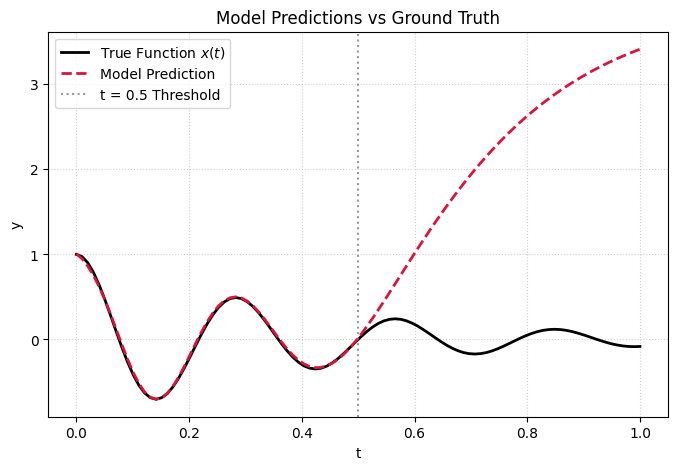

In [ ]:
model.eval()

with torch.no_grad():
    t_test = torch.linspace(0, 1, 100).view(-1, 1)
    y_pred = model(t_test)
    y_true = x(t_test)

    print(t_test.shape,y_pred.shape, y_true.shape)


t_np = t_test.cpu().numpy()
y_pred_np = y_pred.cpu().numpy()
y_true_np = y_true.cpu().numpy()

# Initialize the plot
plt.figure(figsize=(8, 5))

# Plot the true values vs predictions
plt.plot(t_np, y_true_np, label='True Function $x(t)$', color='black', linewidth=2)
plt.plot(t_np, y_pred_np, label='Model Prediction', color='crimson', linestyle='--', linewidth=2)
plt.axvline(x=0.5, color='gray', linestyle=':', alpha=0.8, label='t = 0.5 Threshold')

# Metadata & Styling
plt.title('Model Predictions vs Ground Truth')
plt.xlabel('t')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


# Render
plt.show()





In [ ]:
loss = criterion(y_pred, y_true)
print(f'Test Loss: {loss.item():.4f}')

Test Loss: 0.2925


In [ ]:
t_train_plt = torch.linspace(0,1,100).view(-1, 1)

y_train_plt = x(t_train)


plt.plot(t_train_plt.numpy(), y_train_plt.numpy(), label='True Function')


## Task 2.3

In [ ]:
class Net(nn.Module):
    def __init__(self):
        super(Net,self).__init__()
        activation = nn.Tanh()
        self.net = nn.Sequential(
            nn.Linear(1, 10),
            activation,
            nn.Linear(10, 1),
        )

    def forward(self, x):
        return self.net(x)